# <center> Training on full data

In [1]:
import sys
from pathlib import Path

# Find project root = folder that contains "src"
p = Path().resolve()
while p != p.parent and not (p / "src").exists():
    p = p.parent

if not (p / "src").exists():
    raise RuntimeError("Cannot find project root (folder containing 'src').")

sys.path.insert(0, str(p))  # add project root

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import HTML
mpl.rcParams['animation.embed_limit'] = 500
import pandas as pd
from sklearn.metrics import mean_squared_error
from IPython.display import display
import matplotlib.ticker as ticker
import pickle

import warnings
warnings.simplefilter("ignore", category=pd.errors.PerformanceWarning)

from pandas.errors import PerformanceWarning
warnings.filterwarnings("ignore", category=PerformanceWarning)

import os
os.environ["OMP_NUM_THREADS"] = "1"  # To limit CPU usage and avoid crashes
os.environ["MKL_NUM_THREADS"] = "1"


from src.preprocessing import preprocessing_pipeline
from src.model_NN import train_nn_pipeline
from src.sampling import sample_trajectory, generate_trajectory_video
from src import functions


## Parameters

In [3]:
cols_to_lag = [
    "f_speed",
    "d_ori",
    "min_dist_active",
    "mean_dist_active",
    "mean_angle_active",
    "lateral_balance",
    "n_active_stimuli",
    "is_dots_moving"
]

subsample = 10
horizon = 1

## Context

This notebook focuses on training the model on the full data.

In [4]:
# We download the dict extracted from the pipeline
with open("abs_dict.pkl", "rb") as f:
    abs_dict = pickle.load(f)

#We create a big dataset with all fish
df_abs_raw = functions.stack_dict_pipeline(abs_dict)

#keep only 800000 first rows for faster processing
#df_abs_raw = df_abs_raw.iloc[:800000, :]

print("Dataframe shape : " + str(df_abs_raw.shape))

Dataframe shape : (4702500, 30)


In [5]:
#print percentage of rows with column stimulus == 'inter_stim_pause'
print("Percentage of rows with stimulus == 'inter_stim_pause' : " + str((df_abs_raw['stimulus'] == 'inter_stim_pause').mean() * 100) + "%")

Percentage of rows with stimulus == 'inter_stim_pause' : 45.45454545454545%


In [6]:
df_abs_raw

,frame,stimulus,f_x,f_y,f_ori,d0_x,d0_y,d0_stim,d1_x,d1_y,...,d5_x,d5_y,d5_stim,d6_x,d6_y,d6_stim,d7_x,d7_y,d7_stim,fish_id
0,0,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
1,1,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
2,2,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
3,3,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
4,4,inter_stim_pause,NaN,NaN,NaN,NaN,NaN,inter_stim_pause,NaN,NaN,...,NaN,NaN,none,NaN,NaN,none,NaN,NaN,none,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4702495,313495,CLsemi1800_g0-1_s3.5-3.5,226.0,199.0,0.864185,162.660280,142.866172,CLsemi1800_g0-1_s3.5-3.5,150.0,179.0,...,150.0,179.0,none,150.0,179.0,none,150.0,179.0,none,9
4702496,313496,CLsemi1800_g0-1_s3.5-3.5,226.0,199.0,0.872185,158.997148,136.091130,CLsemi1800_g0-1_s3.5-3.5,150.0,179.0,...,150.0,179.0,none,150.0,179.0,none,150.0,179.0,none,9
4702497,313497,CLsemi1800_g0-1_s3.5-3.5,226.0,199.0,0.872185,158.997148,136.091130,CLsemi1800_g0-1_s3.5-3.5,150.0,179.0,...,150.0,179.0,none,150.0,179.0,none,150.0,179.0,none,9
4702498,313498,CLsemi1800_g0-1_s3.5-3.5,227.0,199.0,0.855185,158.997148,136.091130,CLsemi1800_g0-1_s3.5-3.5,150.0,179.0,...,150.0,179.0,none,150.0,179.0,none,150.0,179.0,none,9


In [7]:
df, df_base = preprocessing_pipeline(df_abs_raw, cols_to_lag=cols_to_lag,horizon_frames=horizon, subsample=subsample) # data for training

------------ Raw dataframe ------------
The dataset contains : 0.4784688995215311% of NaN.
There are few NaN, therefore we make the choice to remove them.
✅ No highly correlated features found.
Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.
------------ Percentage of frame with x number of stimuli  ------------
   Number of active stimuli  Percentage of frames
0                         0              0.452485
1                         4              0.138371
2                         8              0.137960
3                         1              0.132786
4                         6              0.069222
5                         2              0.069177
Created 72 lag features for 8 base columns, using lags from 10 to 90 frames (step=10, horizon ≈ 3.00 s at 30 fps).


MemoryError: Unable to allocate 4.05 GiB for an array with shape (121, 4496351) and data type float64

In [ ]:
df

In [7]:
print("Dataframe shape : " + str(df.shape))

Dataframe shape : (4496349, 133)


✅ Temporal split complete:
  Train: 3597079 rows (80.0%)
  Val:   449635 rows (10.0%)
  Test:  449635 rows (10.0%)
Epoch 1/100 | Train loss: -3.160070 | Val loss: -3.820981
Epoch 2/100 | Train loss: -3.298517 | Val loss: -3.872239
Epoch 3/100 | Train loss: -3.314249 | Val loss: -3.808730
Epoch 4/100 | Train loss: -3.323486 | Val loss: -3.818347
Epoch 5/100 | Train loss: -3.329075 | Val loss: -3.921712
Epoch 6/100 | Train loss: -3.332027 | Val loss: -3.831609
Epoch 7/100 | Train loss: -3.334976 | Val loss: -3.904744
Epoch 8/100 | Train loss: -3.336852 | Val loss: -3.928781
Epoch 9/100 | Train loss: -3.339180 | Val loss: -3.892446
Epoch 10/100 | Train loss: -3.342273 | Val loss: -3.897574
Epoch 11/100 | Train loss: -3.345285 | Val loss: -3.904738
Epoch 12/100 | Train loss: -3.358821 | Val loss: -3.957187
Epoch 13/100 | Train loss: -3.360951 | Val loss: -3.925477
Epoch 14/100 | Train loss: -3.361930 | Val loss: -3.908169
Epoch 15/100 | Train loss: -3.362874 | Val loss: -3.904534
Epoch 16/

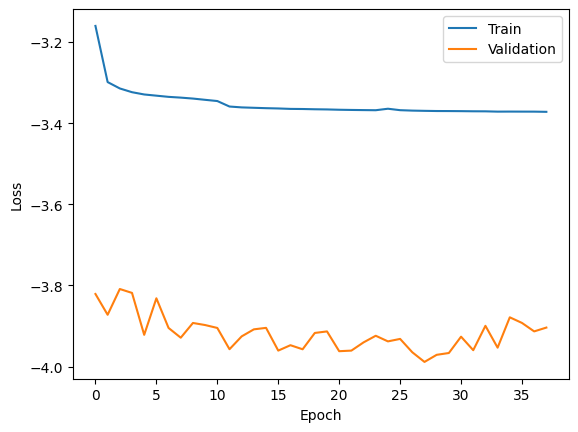

In [8]:
model, scalers, splits = train_nn_pipeline(df, early_stopping=True)

## Test 

In [9]:
# =========================
# Select 1800 test frames with stimuli
# =========================

N = 1800

X_test_df     = splits["test"]["X"].copy()
speed_test_df = splits["test"]["speed"].copy()
ori_test_df   = splits["test"]["d_ori"].copy()

# check column exists
if "n_active_stimuli" not in X_test_df.columns:
    raise KeyError("n_active_stimuli not found in splits['test']['X']")

# keep only rows with stimuli
mask = X_test_df["n_active_stimuli"] > 0

X_test_df     = X_test_df[mask]
speed_test_df = speed_test_df[mask]
ori_test_df   = ori_test_df[mask]

# keep first 1800 frames
X_test_df     = X_test_df.iloc[:N]
speed_test_df = speed_test_df.iloc[:N]
ori_test_df   = ori_test_df.iloc[:N]

print("Selected rows:", len(X_test_df))

Selected rows: 1800


In [10]:
# =========================
# TEST RMSE (speed + d_ori)
# =========================

from torch.utils.data import TensorDataset, DataLoader
import torch

X_test_np = X_test_df.to_numpy(dtype="float32")

batch_size = 32  # change if you want

# 1) Build a test_loader (x, y_speed, y_ori)
y_speed_test_np = speed_test_df.to_numpy(dtype="float32").reshape(-1, 1)
y_ori_test_np   = ori_test_df.to_numpy(dtype="float32").reshape(-1, 1)

test_dataset = TensorDataset(
    torch.from_numpy(X_test_np),
    torch.from_numpy(y_speed_test_np),
    torch.from_numpy(y_ori_test_np),
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

# 2) Sanity check (must be 3)
b = next(iter(test_loader))
print("Batch length:", len(b))
print("Shapes:", [t.shape for t in b])  # expect: [(B,260), (B,1), (B,1)]

# 3) Eval + RMSE
model.eval()

all_pred_speed = []
all_true_speed = []
all_pred_ori   = []
all_true_ori   = []

with torch.no_grad():
    for x_test, y_test_speed, y_test_ori in test_loader:
        out = model(x_test)

        # Expect model outputs 5 params per sample:
        # [mu_st, sigma_st_raw, p_pos_raw, mu_ln, sigma_ln_raw]
        mu_st    = out[:, 0]
        p_pos    = torch.sigmoid(out[:, 2])
        mu_ln    = out[:, 3]
        sigma_ln_raw = torch.nn.functional.softplus(out[:, 4]) + 1e-6
        
        sigma_min, sigma_max = 1e-3, 1.0  # à ajuster (souvent 0.3–1.5 max)
        sigma_ln = sigma_min + (sigma_max - sigma_min) * torch.sigmoid(sigma_ln_raw)

        # Orientation point prediction: Student-t mean
        mu_st = out[:, 0]
        sigma_st = torch.nn.functional.softplus(out[:, 1]) + 1e-6

        # Student-t sample: mu + sigma * t_nu
        t = torch.distributions.StudentT(df=5).sample(mu_st.shape).to(mu_st.device)
        pred_ori = mu_st + sigma_st * t

        # Speed point prediction: E[ZILN] = p_pos * exp(mu + 0.5*sigma^2)
        p_pos = torch.sigmoid(out[:, 2])
        mu_ln = out[:, 3]
        sigma_ln = sigma_min + (sigma_max - sigma_min) * torch.sigmoid(out[:, 4])  # raw -> sigmoid

        u = torch.rand_like(p_pos)
        b = (u < p_pos).float()  # Bernoulli
        pred_speed = b * torch.exp(mu_ln + sigma_ln * torch.randn_like(mu_ln))

        all_pred_speed.append(pred_speed)
        all_true_speed.append(y_test_speed.squeeze(-1))

        all_pred_ori.append(pred_ori)
        all_true_ori.append(y_test_ori.squeeze(-1))

all_pred_speed = torch.cat(all_pred_speed, dim=0)
all_pred_speed = scalers["speed"].inverse_transform(all_pred_speed.reshape(-1, 1)).flatten()

all_true_speed = torch.cat(all_true_speed, dim=0)
all_true_speed = scalers["speed"].inverse_transform(all_true_speed.reshape(-1, 1)).flatten()

all_pred_ori   = torch.cat(all_pred_ori, dim=0)
all_pred_ori   = scalers["ori"].inverse_transform(all_pred_ori.reshape(-1, 1)).flatten()

all_true_ori   = torch.cat(all_true_ori, dim=0)
all_true_ori   = scalers["ori"].inverse_transform(all_true_ori.reshape(-1, 1)).flatten()

rmse_speed = np.sqrt(np.mean((all_pred_speed - all_true_speed) ** 2))
rmse_ori   = np.sqrt(np.mean((all_pred_ori   - all_true_ori)   ** 2))

Batch length: 3
Shapes: [torch.Size([32, 131]), torch.Size([32, 1]), torch.Size([32, 1])]


# <center> RESULTS 

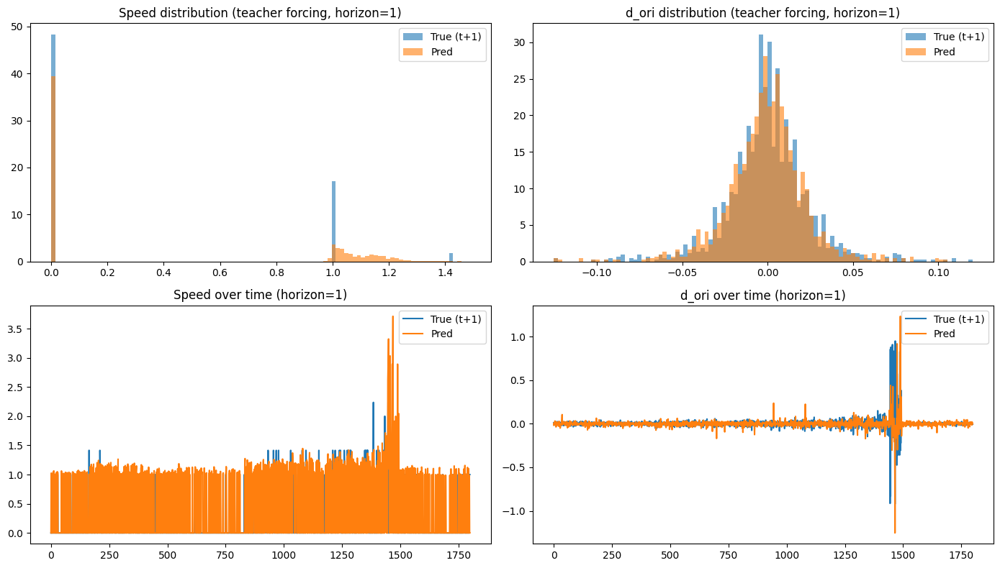

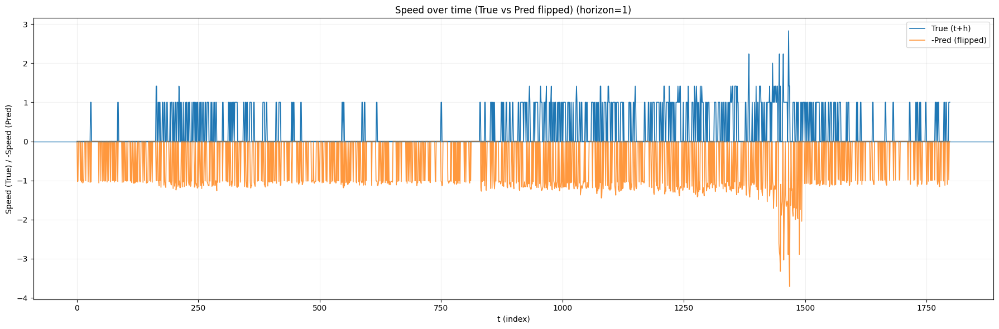

In [11]:
# convert to numpy
pred_speed = all_pred_speed
true_speed = all_true_speed
pred_ori   = all_pred_ori
true_ori   = all_true_ori

# -------------------------
# Align properly (shift by horizon)
# -------------------------
n = min(len(pred_speed), len(true_speed) - horizon)

pred_speed = pred_speed[:n]
pred_ori   = pred_ori[:n]

true_speed_shifted = true_speed[horizon:horizon+n]
true_ori_shifted   = true_ori[horizon:horizon+n]

t = np.arange(n)

# -------------------------
# Robust zoom ranges
# -------------------------
speed_min = np.percentile(np.concatenate([true_speed_shifted, pred_speed]), 1)
speed_max = np.percentile(np.concatenate([true_speed_shifted, pred_speed]), 99)

ori_min = np.percentile(np.concatenate([true_ori_shifted, pred_ori]), 1)
ori_max = np.percentile(np.concatenate([true_ori_shifted, pred_ori]), 99)

# -------------------------
# Plot
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# ---- Speed distribution ----
axes[0, 0].hist(true_speed_shifted, bins=100, range=(speed_min, speed_max),
                alpha=0.6, density=True, label="True (t+1)")
axes[0, 0].hist(pred_speed, bins=100, range=(speed_min, speed_max),
                alpha=0.6, density=True, label="Pred")
axes[0, 0].set_title("Speed distribution (teacher forcing, horizon=1)")
axes[0, 0].legend()

# ---- d_ori distribution ----
axes[0, 1].hist(true_ori_shifted, bins=100, range=(ori_min, ori_max),
                alpha=0.6, density=True, label="True (t+1)")
axes[0, 1].hist(pred_ori, bins=100, range=(ori_min, ori_max),
                alpha=0.6, density=True, label="Pred")
axes[0, 1].set_title("d_ori distribution (teacher forcing, horizon=1)")
axes[0, 1].legend()

# ---- Speed over time ----
axes[1, 0].plot(t, true_speed_shifted, label="True (t+1)")
axes[1, 0].plot(t, pred_speed, label="Pred")
axes[1, 0].set_title("Speed over time (horizon=1)")
axes[1, 0].legend()

# ---- d_ori over time ----
axes[1, 1].plot(t, true_ori_shifted, label="True (t+1)")
axes[1, 1].plot(t, pred_ori, label="Pred")
axes[1, 1].set_title("d_ori over time (horizon=1)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# --- Split view: True up, Pred down ---
true_s = true_speed_shifted
pred_s = pred_speed
t = np.arange(len(pred_s))



plt.figure(figsize=(18, 6))
plt.plot(t, true_s, label="True (t+h)", linewidth=1.2)
plt.plot(t, -pred_s, label="-Pred (flipped)", linewidth=1.2, alpha=0.8)


plt.axhline(0, linewidth=1)
plt.title(f"Speed over time (True vs Pred flipped) (horizon={horizon})")
plt.xlabel("t (index)")
plt.ylabel("Speed (True) / -Speed (Pred)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


# <center> SAMPLING and VIDEO

#### Let's select a trial to have "start data" and true behavior comparison.

In [12]:
# 1) Detect onset
prev = df_abs_raw['stimulus'].shift(1)
onset_idx = df_abs_raw.index[(prev == "inter_stim_pause") & (df_abs_raw['stimulus'] != "inter_stim_pause")][0]

# 2) find end of the trial
after = df_abs_raw.loc[onset_idx:]
end_idx = after.index[after['stimulus'] == "inter_stim_pause"][0]
# garder uniquement ce premier trial
df_trial_base = df_abs_raw.loc[onset_idx:end_idx - 1].copy()

### Video of the real behavior of the fish

In [13]:
df, df_trial_base = preprocessing_pipeline(df_trial_base, cols_to_lag=cols_to_lag, horizon_frames=horizon, subsample=subsample)

------------ Raw dataframe ------------
The dataset contains : 0.0% of NaN.
There are few NaN, therefore we make the choice to remove them.
✅ No highly correlated features found.
Removed rows with |d_ori| > 1 radians. There are artefacts representing less than 4% of the data.
------------ Percentage of frame with x number of stimuli  ------------
   Number of active stimuli  Percentage of frames
0                         4                   1.0
Created 72 lag features for 8 base columns, using lags from 10 to 90 frames (step=10, horizon ≈ 3.00 s at 30 fps).


In [14]:
anim = generate_trajectory_video(df_trial_base, horizon_frames=horizon)
from IPython.display import HTML
HTML(anim.to_jshtml())

### Video of the model behavior

In [17]:
window, prediction_sampling, params_sampling = sample_trajectory(df_trial_base, model, scalers, cols_to_lag=cols_to_lag, horizon_frames=horizon, subsample=subsample)

anim = generate_trajectory_video(window, horizon_frames=horizon)
from IPython.display import HTML
HTML(anim.to_jshtml())

Created 720 lag features for 8 base columns, using lags from 1 to 90 frames (step=1, horizon ≈ 3.00 s at 30 fps).


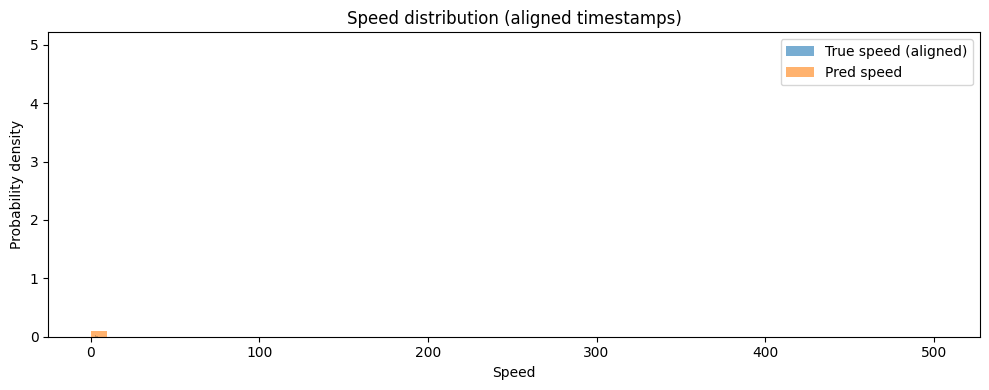

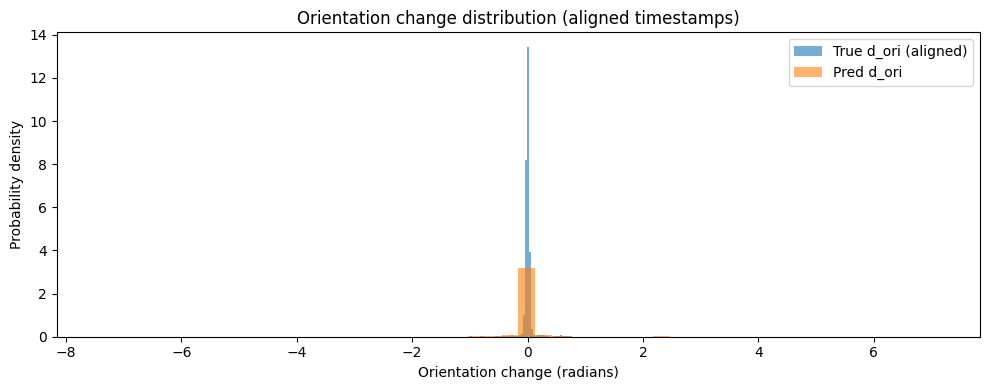

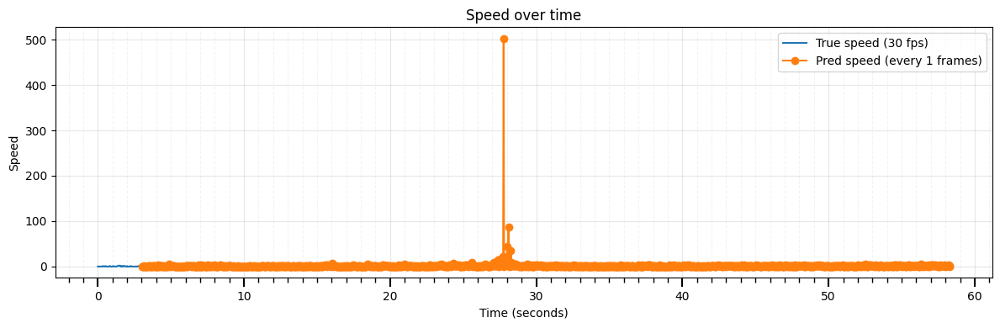

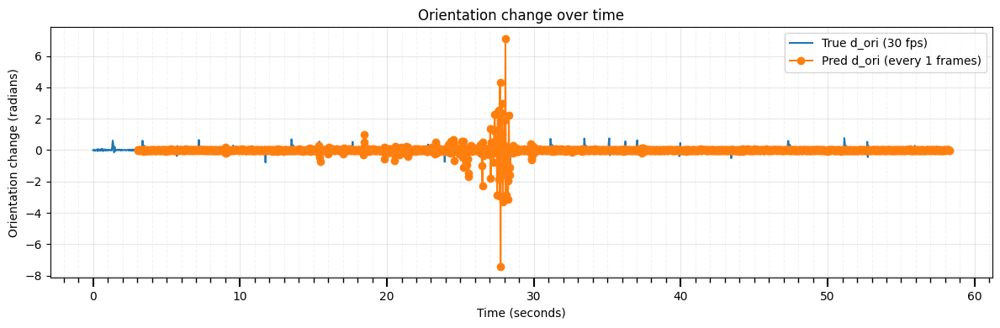

In [18]:
horizon_frames = horizon
seed_len = int(3 * 30 + 1)
fps=30

# -------------------------
# 0) Prepare arrays
# -------------------------
pred_arr = np.asarray(prediction_sampling, dtype=float)
pred_speed = pred_arr[:, 0]
pred_dori  = pred_arr[:, 1]

# Make a clean positional index column
dfp = df_trial_base.copy()
dfp = dfp.reset_index(drop=False)
dfp["idx"] = np.arange(len(dfp))

# -------------------------
# 1) Build the prediction timestamps (in frames)
# -------------------------
t0 = (seed_len - 1) + horizon_frames
t_pred_frames = t0 + np.arange(len(pred_speed)) * horizon_frames

mask = t_pred_frames < len(dfp)
t_pred_frames = t_pred_frames[mask]
pred_speed = pred_speed[mask]
pred_dori  = pred_dori[mask]
t_pred_sec = t_pred_frames / float(fps)

# -------------------------
# 2) Extract TRUE series
# -------------------------
true_speed_full = dfp["f_speed"].to_numpy(dtype=float)
true_dori_full  = dfp["d_ori"].to_numpy(dtype=float)
t_full_sec      = dfp["idx"].to_numpy(dtype=float) / float(fps)

true_speed_aligned = dfp.iloc[t_pred_frames]["f_speed"].to_numpy(dtype=float)
true_dori_aligned  = dfp.iloc[t_pred_frames]["d_ori"].to_numpy(dtype=float)

# -------------------------
# 3) Plot A: Distributions (aligned)
# -------------------------
plt.figure(figsize=(10, 4))
plt.hist(true_speed_aligned, bins=50, alpha=0.6, density=True, label="True speed (aligned)")
plt.hist(pred_speed, bins=50, alpha=0.6, density=True, label="Pred speed")
plt.title("Speed distribution (aligned timestamps)")
plt.xlabel("Speed")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(true_dori_aligned, bins=50, alpha=0.6, density=True, label="True d_ori (aligned)")
plt.hist(pred_dori, bins=50, alpha=0.6, density=True, label="Pred d_ori")
plt.title("Orientation change distribution (aligned timestamps)")
plt.xlabel("Orientation change (radians)")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.show()

# -------------------------
# 4) Plot B: Time series
# -------------------------
plt.figure(figsize=(12, 4))
plt.plot(t_full_sec, true_speed_full, label="True speed (30 fps)")
plt.plot(t_pred_sec, pred_speed, marker="o", linestyle="-", label=f"Pred speed (every {horizon_frames} frames)")
plt.title("Speed over time")
plt.xlabel("Time (seconds)")
plt.ylabel("Speed")
plt.legend()

ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.tick_params(axis='x', which='major', length=8, width=1.5)
ax.tick_params(axis='x', which='minor', length=4, width=1)
ax.grid(which='major', linestyle='-', alpha=0.3)
ax.grid(which='minor', linestyle='--', alpha=0.15)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(t_full_sec, true_dori_full, label="True d_ori (30 fps)")
plt.plot(t_pred_sec, pred_dori, marker="o", linestyle="-", label=f"Pred d_ori (every {horizon_frames} frames)")
plt.title("Orientation change over time")
plt.xlabel("Time (seconds)")
plt.ylabel("Orientation change (radians)")
plt.legend()

ax = plt.gca()
ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
ax.tick_params(axis='x', which='major', length=8, width=1.5)
ax.tick_params(axis='x', which='minor', length=4, width=1)
ax.grid(which='major', linestyle='-', alpha=0.3)
ax.grid(which='minor', linestyle='--', alpha=0.15)

plt.tight_layout()
plt.show()

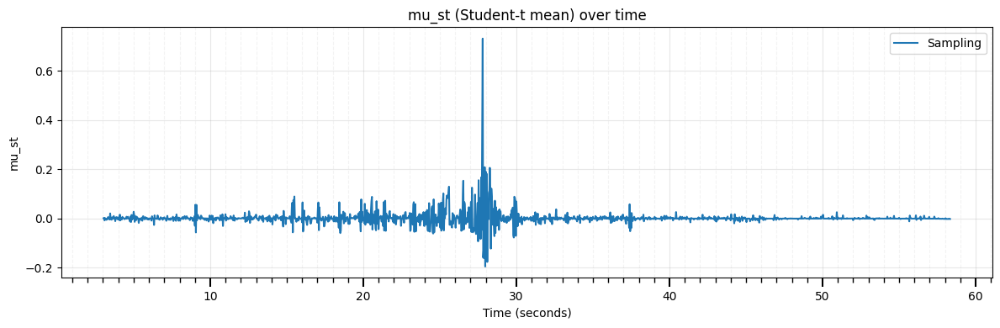

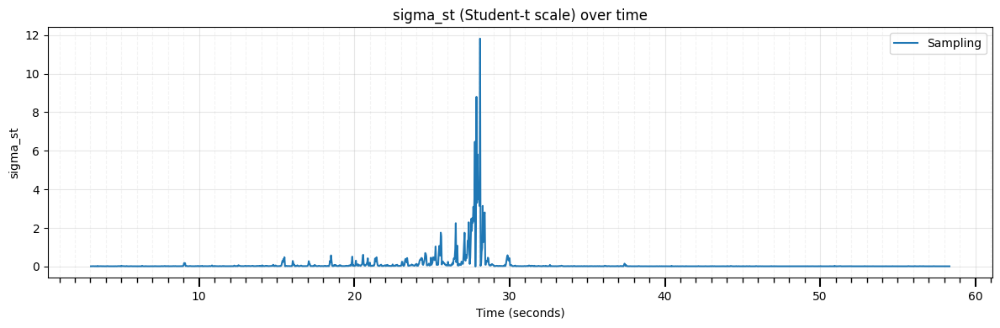

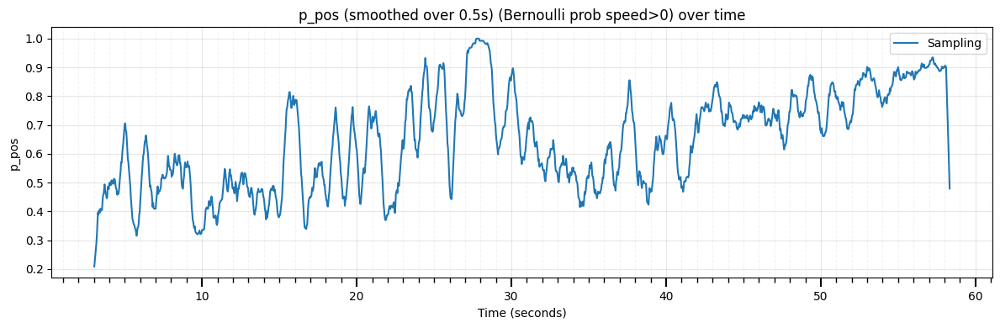

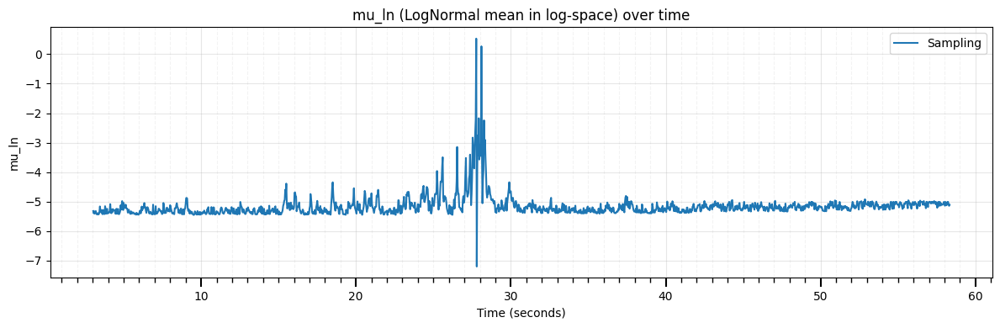

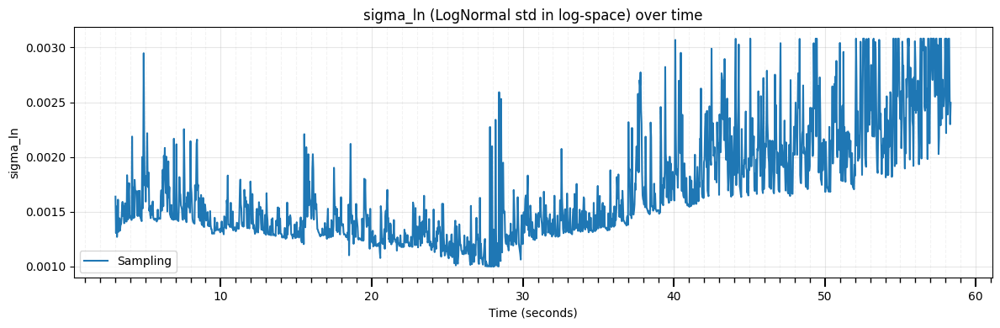

In [19]:
def postprocess_params(raw_out):
    raw_out = np.asarray(raw_out, dtype=float)

    mu_st = raw_out[:, 0]
    sigma_st_raw = raw_out[:, 1]
    p_pos_raw = raw_out[:, 2]
    mu_ln = raw_out[:, 3]
    sigma_ln_raw = raw_out[:, 4]

    # sigma_st = softplus(raw) + eps
    sigma_st = np.log1p(np.exp(sigma_st_raw)) + 1e-6

    # p_pos = sigmoid(raw)
    p_pos = 1.0 / (1.0 + np.exp(-p_pos_raw))

    # sigma_ln = 1e-3 + (1-1e-3) * sigmoid(raw)
    sig = 1.0 / (1.0 + np.exp(-sigma_ln_raw))
    sigma_ln = 1e-3 + (1.0 - 1e-3) * sig

    return {
        "mu_st": mu_st,
        "sigma_st": sigma_st,
        "p_pos": p_pos,
        "mu_ln": mu_ln,
        "sigma_ln": sigma_ln,
    }

def smooth_series(y, fps, window_sec=0.5):
    y = np.asarray(y, dtype=float)
    w = max(1, int(round(window_sec * fps)))
    kernel = np.ones(w, dtype=float) / w
    return np.convolve(y, kernel, mode="same")


# -------------------------
# 0) Postprocess sampling only
# -------------------------
params_sampling = np.asarray(params_sampling, dtype=float)
pp_samp = postprocess_params(params_sampling)

# -------------------------
# 1) Time axis for sampling (seconds)
# -------------------------
seed_len = int(3 * 30 + 1)
t0_frame = (seed_len - 1) + horizon_frames

t_samp_frames = t0_frame + np.arange(len(params_sampling)) * horizon_frames
t_samp_sec = t_samp_frames / float(fps)

# -------------------------
# 2) Plot (one figure per parameter)
#    -> p_pos plot is SMOOTHED over 0.5s
# -------------------------
params_names = [
    ("mu_st",    "mu_st (Student-t mean)"),
    ("sigma_st", "sigma_st (Student-t scale)"),
    ("p_pos",    "p_pos (Bernoulli prob speed>0)"),
    ("mu_ln",    "mu_ln (LogNormal mean in log-space)"),
    ("sigma_ln", "sigma_ln (LogNormal std in log-space)"),
]

for key, title in params_names:
    y = pp_samp[key]

    if key == "p_pos":
        y = smooth_series(y, fps=fps, window_sec=0.5)
        title = "p_pos (smoothed over 0.5s) (Bernoulli prob speed>0)"

    plt.figure(figsize=(12, 4))
    plt.plot(t_samp_sec, y, label="Sampling")
    plt.title(title + " over time")
    plt.xlabel("Time (seconds)")
    plt.ylabel(key)
    plt.legend()

    ax = plt.gca()
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(1))
    ax.tick_params(axis="x", which="major", length=8, width=1.5)
    ax.tick_params(axis="x", which="minor", length=4, width=1)
    ax.grid(which="major", linestyle="-", alpha=0.3)
    ax.grid(which="minor", linestyle="--", alpha=0.15)

    plt.tight_layout()
    plt.show()